# Experimental: cross-section of the wind component parallel to the section, with a map

**This is an experimental example.** It reproduces the Metview gallery example [Cross Section Parallel Wind Component with Map](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_wind_parallel.html) with earthkit-geo, xarray and earthkit-plots. It is the companion of [cross_section_wind_normal.ipynb](cross_section_wind_normal.ipynb), which shows the component normal to the section along the same line. It uses the new `earthkit.geo.polyline` module, whose interface may still change. The figure has two panels: a map with the 500 hPa geopotential height (contours) and the cross-section line (red) above, and the cross-section of the wind parallel component below.

The parallel wind component is the wind along the section, i.e. the wind component in the direction of the line. It is positive in the direction of travel, which is towards the north-east here, because the line goes from (30.30°N, 79.83°W) to (36.95°N, 63.92°W). It is computed by projecting the wind on the unit tangent vector of the line. Metview titles this plot "Cross section of wind speed", but it is **not** the wind speed: it is the signed, along-line component of the horizontal wind, so it can be negative.

The notebook reads a GRIB file. It contains forecast data of superstorm Sandy on 2012-10-29 00 UTC.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
from datetime import datetime

import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import polyline_normals, sample_polyline

## Load the data

The file contains the fields `r`, `u`, `v` and `z` on the pressure levels 1000, 925, 850, 700, 500, 400, 300, 250, 200, 150 and 100 hPa, for a single date and a single step (the analysis time, step 0). It is a GRIB1 file on a regular 0.25° latitude-longitude grid over the area 25–40°N, 84–60°W. The wind components `u` and `v` are the east and north components, because the file is not relative to the grid. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "sandy_pl_025.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

sandy_pl_025.grib:   0%|          | 0.00/516k [00:00<?, ?B/s]

44 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,r,2012-10-29,2012-10-29,0 days,1000,pressure,0,regular_ll
1,z,2012-10-29,2012-10-29,0 days,1000,pressure,0,regular_ll
2,u,2012-10-29,2012-10-29,0 days,1000,pressure,0,regular_ll
3,v,2012-10-29,2012-10-29,0 days,1000,pressure,0,regular_ll
4,r,2012-10-29,2012-10-29,0 days,925,pressure,0,regular_ll
5,z,2012-10-29,2012-10-29,0 days,925,pressure,0,regular_ll


## Select the wind components and the geopotential at 500 hPa

We select `u` and `v` on all 11 levels, and `z` on 500 hPa only. The geopotential is in m²/s². Dividing it by 98.0665 m²/s² per dam (standard gravity 9.80665 m/s² times 10 m) converts it to geopotential height in dam, which is what Metview contours. The `latitude` and `longitude` coordinates of the field are kept.

In [3]:
u = ds.sel({"parameter.variable": "u"})
v = ds.sel({"parameter.variable": "v"})
z500 = ds.sel({"parameter.variable": "z", "vertical.level": 500})

levels = [f.get("vertical.level") for f in u]
assert levels == [f.get("vertical.level") for f in v], "u and v must have the same levels in the same order"
print(len(u), "u fields, levels (hPa):", levels)
print(len(v), "v fields")
print(len(z500), "z500 field")

# geopotential (m2/s2) -> geopotential height (dam)
z500_dam = z500.to_xarray()["z"] / 98.0665
z500_dam.attrs = {"units": "dam", "long_name": "Geopotential height"}

11 u fields, levels (hPa): [1000, 925, 850, 700, 500, 400, 300, 250, 200, 150, 100]
11 v fields
1 z500 field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (30.30°N, 79.83°W) to (36.95°N, 63.92°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [4]:
lats, lons = sample_polyline([30.30, 36.95], [-79.83, -63.92], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(30.3), np.float64(-79.83)) (np.float64(36.95), np.float64(-63.92))


## Compute the normal vectors

[polyline_normals()](https://earthkit-geo.readthedocs.io) returns the east and north components of the unit normal vector at each point of the line. It uses the same `method` as `sample_polyline()`. The normal vector is on the left of the direction of travel. Here the line goes towards the north-east, so the normal vectors point towards the north-west: `east` is negative and `north` is positive.

In [5]:
east_n, north_n = polyline_normals(lats, lons, method="linear")
print("east:", east_n.min().round(3), "to", east_n.max().round(3))
print("north:", north_n.min().round(3), "to", north_n.max().round(3))

east: -0.463 to -0.436
north: 0.886 to 0.9


## Compute the tangent vectors

The unit tangent vector, which points in the direction of travel, is the normal vector rotated back by 90° clockwise. The normal is the tangent rotated by 90° anti-clockwise to the left, so for the (east, north) components `normal = (-t_north, t_east)`. Hence `t_east = north_n` and `t_north = -east_n`. At the first point the normal is about (-0.436, 0.900), so the tangent is about (0.900, 0.436): it points to the east-north-east, as the line does. The cell below checks that the tangent has unit length and is perpendicular to the normal, which means that the scalar product of the two vectors is zero.

In [6]:
t_east = north_n
t_north = -east_n

assert np.allclose(np.hypot(t_east, t_north), 1.0), "the tangent must have unit length"
assert np.allclose(t_east * east_n + t_north * north_n, 0.0), "the tangent must be perpendicular to the normal"
print(f"tangent at the first point: ({t_east[0]:.3f}, {t_north[0]:.3f})")

tangent at the first point: (0.900, 0.436)


## Regrid onto the line

`u` and `v` are regridded onto the 200 points of the line, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each pressure level. MIR may print some `GridUnknownError` and `ECCODES` lines during this step (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message), they come from the C libraries and do not stop the regridding.

In [7]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}

u_line = ekg.regrid(u, out_grid=out_grid)
v_line = ekg.regrid(v, out_grid=out_grid)
print(len(u_line), "u fields, shape of the values:", u_line[0].values.shape)
print(len(v_line), "v fields, shape of the values:", v_line[0].values.shape)

11 u fields, shape of the values: (200,)
11 v fields, shape of the values: (200,)


ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. O

## Compute the parallel wind component

At each level and point the parallel component is the scalar product of the wind vector with the unit tangent vector: `wp = u * t_east + v * t_north`. It is positive in the direction of travel, i.e. towards the north-east.

In [8]:
u_values = np.stack([f.values for f in u_line])  # (level, point)
v_values = np.stack([f.values for f in v_line])
wp = u_values * t_east + v_values * t_north
print(wp.shape, "NaNs:", int(np.isnan(wp).sum()))
print(f"wp from {wp.min():.1f} to {wp.max():.1f} m/s")

(11, 200) NaNs: 0
wp from -18.6 to 33.5 m/s


**Sign convention.** The signs of the parallel component match the Metview plot. Metview shows a purple (positive) band in the west, from about 150 to 900 hPa and strongest at 300–500 hPa near 78–76°W, a small orange (negative) pocket at about 250 hPa near 76–74°W, and orange (negative) low levels in the east, at 700–1000 hPa from about 68°W to 64°W. The cell below prints the mean values of `wp` in these three regions: they are positive, negative and negative, respectively. So the tangent built from `polyline_normals()` points in the same direction as the one of Metview, i.e. in the direction of travel of the line, towards the north-east.

In [9]:
i400 = levels.index(400)
i925 = levels.index(925)
i250 = levels.index(250)
print(f"mean wp at 400 hPa, west of 76°W: {wp[i400, lons < -76].mean():.1f} m/s")
print(f"mean wp at 925 hPa, east of 67°W: {wp[i925, lons > -67].mean():.1f} m/s")
in_pocket = (lons > -77) & (lons < -74)
print(f"mean wp at 250 hPa, between 77°W and 74°W: {wp[i250, in_pocket].mean():.1f} m/s")

mean wp at 400 hPa, west of 76°W: 26.9 m/s
mean wp at 925 hPa, east of 67°W: -15.8 m/s
mean wp at 250 hPa, between 77°W and 74°W: -8.4 m/s


## Build an Xarray Dataset

We build a Dataset with the parallel component `wp`, and the wind components `u` and `v` on the line, on the dimensions `level` (hPa) and `distance` (km). The distance is the cumulative length of the path along the sampled points. It is the sum of the haversine distances (in metres, so we divide by 1000) between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`. The levels are sorted in ascending order.

In [10]:
# cumulative path length along the sampled points, in km
step_length = np.array([
    haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)
])
distance = np.concatenate([[0.0], np.cumsum(step_length)]) / 1000

xs = xr.Dataset(
    {
        "wp": (
            ("level", "distance"),
            wp,
            {"units": "m s-1", "long_name": "Wind parallel component"},
        ),
        "u": (
            ("level", "distance"),
            u_values,
            {"units": "m s-1", "long_name": "U component of wind"},
        ),
        "v": (
            ("level", "distance"),
            v_values,
            {"units": "m s-1", "long_name": "V component of wind"},
        ),
    },
    coords={
        "level": ("level", levels, {"units": "hPa"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
).sortby("level")
xs

<xarray.Dataset> Size: 58kB
Dimensions:    (level: 11, distance: 200)
Coordinates:
  * level      (level) int64 88B 100 150 200 250 300 400 500 700 850 925 1000
  * distance   (distance) float64 2kB 0.0 8.527 17.05 ... 1.64e+03 1.648e+03
    latitude   (distance) float64 2kB 30.3 30.33 30.37 ... 36.88 36.92 36.95
    longitude  (distance) float64 2kB -79.83 -79.75 -79.67 ... -64.0 -63.92
Data variables:
    wp         (level, distance) float64 18kB 19.48 19.58 ... -10.27 -10.19
    u          (level, distance) float64 18kB 13.32 13.4 13.48 ... -13.9 -13.76
    v          (level, distance) float64 18kB 17.2 17.27 17.35 ... 4.411 4.323

## Plot the map and the cross-section in one figure

We use one earthkit-plots `Figure` with two rows: a map in the first row and an ordinary (non-map) subplot in the second row, which is taller. The panels are added with `add_map()` and `add_subplot()`.

**Map.** The area is 25–40°N, 84–60°W, in a plain latitude-longitude projection. It has grey land, light blue sea, coastlines and 5° grid lines. The geopotential height at 500 hPa is drawn with black contour lines every 4 dam, with labels. The cross-section line is red and thick, and the title is "Z 500 hPa".

**Cross-section.** The filled contours of `wp` use the levels from -36 to 36 m/s every 4 m/s, with the matplotlib colormap `PuOr`. It goes from orange for negative values to purple for positive values. This is the same palette as the ColorBrewer `PuOr` reversed, because ColorBrewer's own order goes from purple to orange. The colour bar is added with the `legend()` method of the figure. The vertical axis is the logarithmic pressure, with 1000 hPa at the bottom and 100 hPa at the top. The horizontal axis has 8 ticks where the line crosses the longitudes 78°W, 76°W, … and 64°W. They are labelled with the latitude (2 decimals) and the longitude of the crossing, which are found by linear interpolation along the line.

Two details need explanation:

- `resample=False` is needed for `contourf()` of the cross-section. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-pressure section.
- The logarithmic axis, the axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

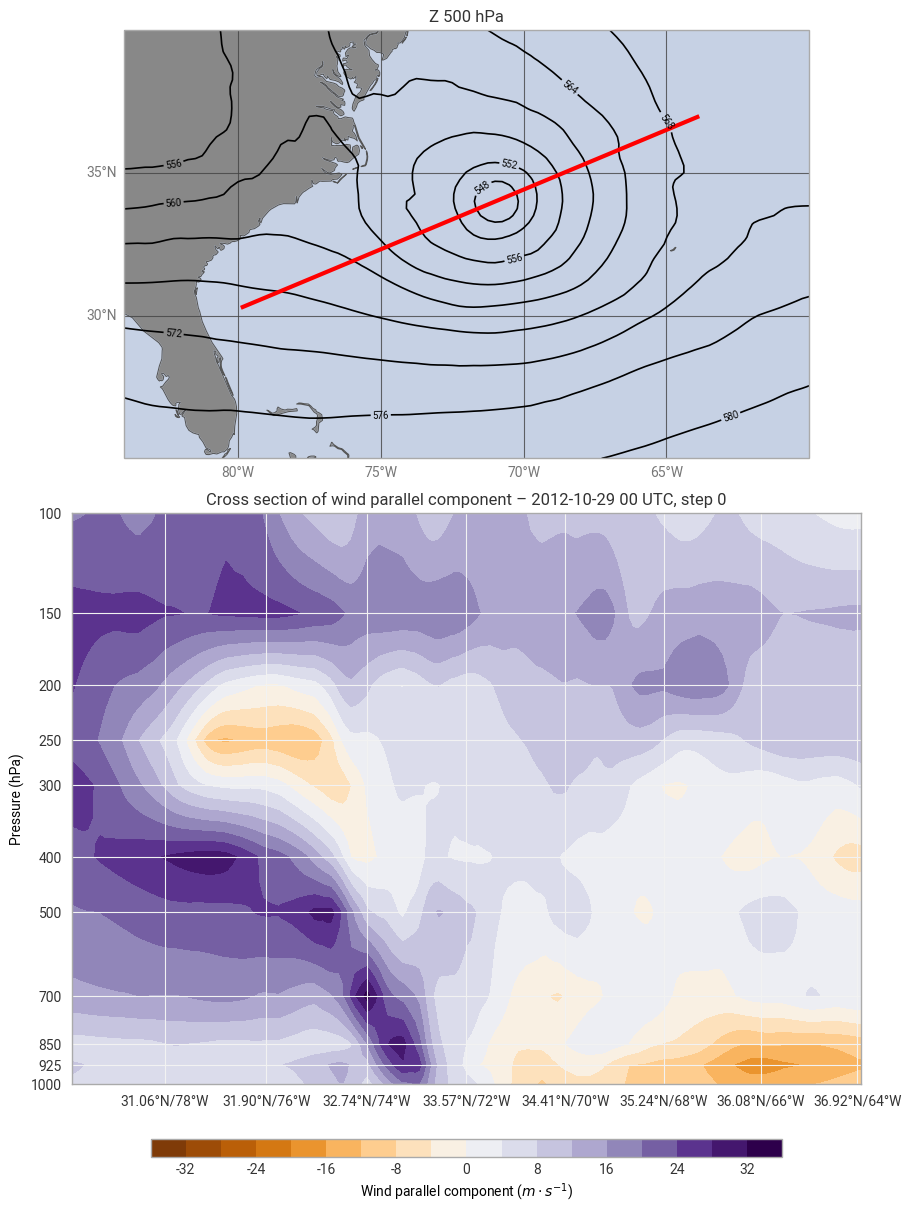

In [11]:
import cartopy.crs as ccrs  # plain latitude-longitude projection for the map

base_date = datetime(2012, 10, 29, 0)
wp_levels = list(range(-36, 37, 4))

fig = ekp.Figure(rows=2, columns=1, figsize=(9, 12), height_ratios=[3, 4])

# --- map: z500 and the cross-section line ---
m = fig.add_map(domain=[-84, -60, 25, 40], crs=ccrs.PlateCarree())  # [west, east, south, north]
m.land(color="#888888")
m.ocean(color="#c6d1e4")
m.coastlines()
m.gridlines(xstep=5, ystep=5, color="#434343", linewidth=0.8)
m.contour(
    z500_dam,
    style=ekp.styles.Contour(levels=list(range(400, 640, 4)), colors="black", labels=True, linewidths=1.2),
    resample=False,
)
m.line(x=[lons[0], lons[-1]], y=[lats[0], lats[-1]], color="red", linewidth=3)
m.title("Z 500 hPa")

# --- cross-section: wind parallel component ---
c = fig.add_subplot()
c.contourf(
    xs["wp"],
    x="distance",
    y="level",
    style=ekp.styles.Style(levels=wp_levels, colors="PuOr"),
    resample=False,
)
fig.legend(subplots=[c])

# 8 ticks where the line crosses the longitudes 78W ... 64W (lons increase along the line)
tick_lons = np.arange(-78, -63, 2)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{lat:.2f}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]

ax = c.ax
ax.set_yscale("log")
ax.set_ylim(1000, 100)  # 1000 hPa at the bottom, 100 hPa at the top
pressure_ticks = [1000, 925, 850, 700, 500, 400, 300, 250, 200, 150, 100]
ax.set_yticks(pressure_ticks)
ax.set_yticklabels([str(p) for p in pressure_ticks])
ax.minorticks_off()
ax.set_xlim(distance[0], distance[-1])
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Pressure (hPa)")
ax.set_title(f"Cross section of wind parallel component – {base_date:%Y-%m-%d %H} UTC, step 0")

fig.show()